# Heart Disease

## Câu 3. Tương quan Pearson

### Yêu cầu

Khảo sát tương quan Pearson, biểu diễn heatmap có giá trị và loại thuộc tính tương quan cao.

### Dữ liệu và phương pháp

Thuộc tính quyết định: target. Sử dụng toàn bộ dữ liệu được cung cấp. Do đề không ấn định phép chia Heart, sử dụng quy ước huấn luyện 70%, kiểm thử 30%, random_state=42. Tương quan cao được quy ước là |r| ≥ 0,8 giữa các thuộc tính đầu vào; giữ cột đứng trước trong thứ tự gốc.

In [1]:
print("Đặng Ngọc Hiếu - 6451071024")

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "datasets").is_dir():
    if (ROOT / "6451071024_Lab2" / "datasets").is_dir():
        ROOT = ROOT / "6451071024_Lab2"
        break
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục datasets của LAB2.")
    ROOT = ROOT.parent
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", font="DejaVu Sans")


raw = pd.read_csv(ROOT / "datasets/heart/heart.csv", skipinitialspace=True)
if raw.shape[1] != 14 or raw.empty:
    raise ValueError("Dữ liệu Heart phải có đủ 14 cột.")
data = raw.dropna().rename(columns={
    "cp": "chest_pain_type",
    "trestbps": "resting_blood_pressure",
    "chol": "cholesterol",
    "fbs": "fasting_blood_sugar",
    "restecg": "rest_ecg",
    "thalach": "max_heart_rate_achieved",
    "exang": "exercise_induced_angina",
    "oldpeak": "st_depression",
    "slope": "st_slope",
    "ca": "num_major_vessels",
    "thal": "thalassemia",
}, errors="raise")
TARGET = "target"
if not set(data[TARGET].unique()).issubset({0, 1}):
    raise ValueError("Nhãn Heart chỉ nhận 0 hoặc 1.")


Đặng Ngọc Hiếu - 6451071024


Đặng Ngọc Hiếu - 6451071024
Quy ước tương quan cao: |r| >= 0.8


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
age,1.000000,-0.098447,-0.068653,0.279351,0.213678,0.121308,-0.116211,-0.398522,0.096801,0.210013,-0.168814,0.276326,0.068001
sex,-0.098447,1.000000,-0.049353,-0.056769,-0.197912,0.045032,-0.058196,-0.044020,0.141664,0.096093,-0.030711,0.118261,0.210041
chest_pain_type,-0.068653,-0.049353,1.000000,0.047608,-0.076904,0.094444,0.044421,0.295762,-0.394280,-0.149230,0.119717,-0.181053,-0.161736
resting_blood_pressure,0.279351,-0.056769,0.047608,1.000000,0.123174,0.177531,-0.114103,-0.046698,0.067616,0.193216,-0.121475,0.101389,0.062210
cholesterol,0.213678,-0.197912,-0.076904,0.123174,1.000000,0.013294,-0.151040,-0.009940,0.067023,0.053952,-0.004038,0.070511,0.098803
fasting_blood_sugar,0.121308,0.045032,0.094444,0.177531,0.013294,1.000000,-0.084189,-0.008567,0.025665,0.005747,-0.059894,0.137979,-0.032019
rest_ecg,-0.116211,-0.058196,0.044421,-0.114103,-0.151040,-0.084189,1.000000,0.044123,-0.070733,-0.058770,0.093045,-0.072042,-0.011981
max_heart_rate_achieved,-0.398522,-0.044020,0.295762,-0.046698,-0.009940,-0.008567,0.044123,1.000000,-0.378812,-0.344187,0.386784,-0.213177,-0.096439
exercise_induced_angina,0.096801,0.141664,-0.394280,0.067616,0.067023,0.025665,-0.070733,-0.378812,1.000000,0.288223,-0.257748,0.115739,0.206754
st_depression,0.210013,0.096093,-0.149230,0.193216,0.053952,0.005747,-0.058770,-0.344187,0.288223,1.000000,-0.577537,0.222682,0.210244


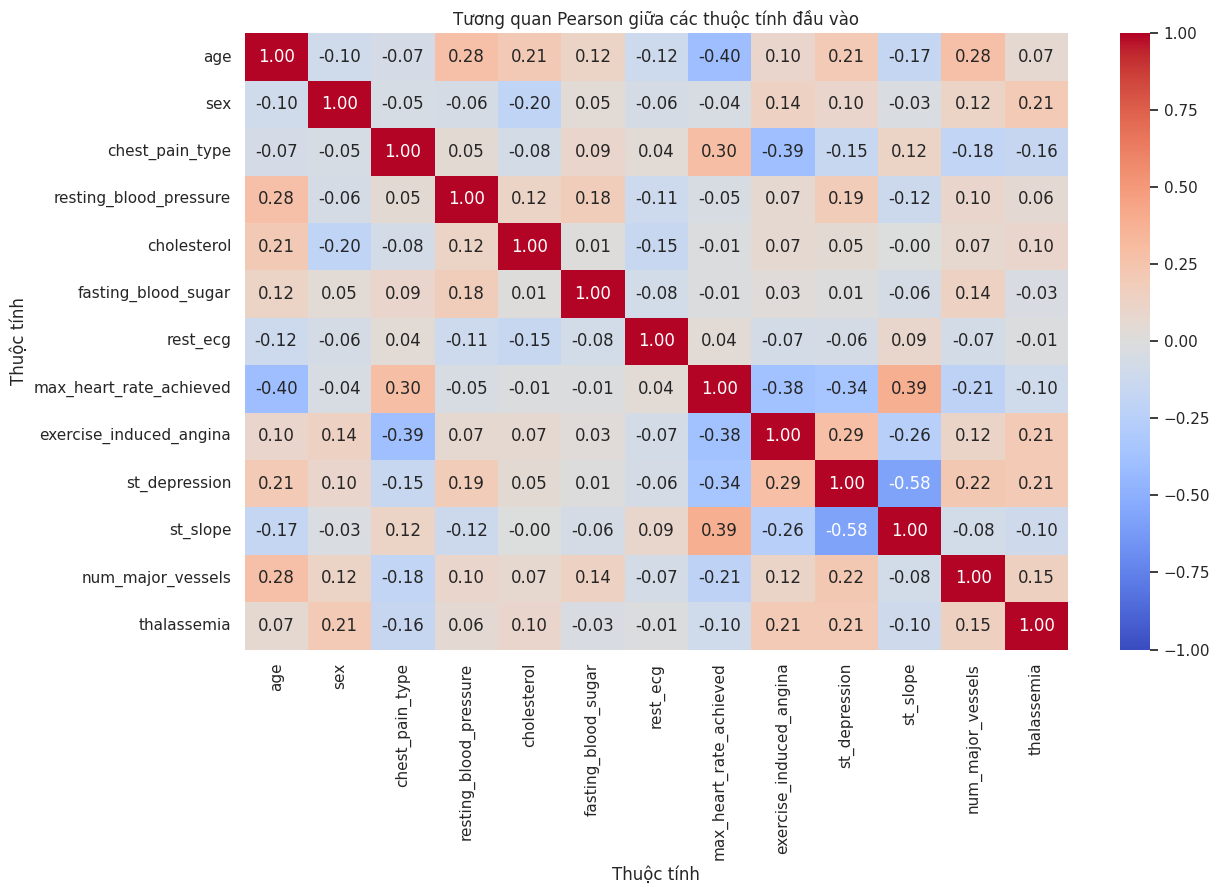

,Cột giữ,Cột loại,Pearson r


Các cột loại: Không có
Kích thước trước loại cột: (303, 14)
Kích thước sau loại cột: (303, 14)


In [2]:
print("Đặng Ngọc Hiếu - 6451071024")

# Pearson chỉ có ý nghĩa trực tiếp trên các cột số, không mã hóa nhãn để loại cột.
numeric = data.drop(columns=TARGET).select_dtypes(include="number")
CORRELATION_THRESHOLD = 0.8  # Quy ước triển khai; đề không ấn định ngưỡng số.
corr = numeric.corr(method="pearson")
print("Quy ước tương quan cao: |r| >=", CORRELATION_THRESHOLD)
display(corr)
plt.figure(figsize=(max(7, len(corr)), max(5, len(corr)*0.7)))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Tương quan Pearson giữa các thuộc tính đầu vào")
plt.xlabel("Thuộc tính")
plt.ylabel("Thuộc tính")
plt.tight_layout()
plt.show()
plt.close()

# Xét theo thứ tự cột gốc; giữ cột trước, bỏ cột sau nếu tương quan cao với cột giữ.
drop_columns = []
pairs = []
for j, column in enumerate(corr.columns):
    for previous in corr.columns[:j]:
        value = corr.loc[previous, column]
        if previous not in drop_columns and pd.notna(value) and abs(value) >= CORRELATION_THRESHOLD:
            drop_columns.append(column)
            pairs.append({"Cột giữ": previous, "Cột loại": column, "Pearson r": value})
            break
display(pd.DataFrame(pairs, columns=["Cột giữ", "Cột loại", "Pearson r"]))
print("Các cột loại:", drop_columns if drop_columns else "Không có")
print("Kích thước trước loại cột:", data.shape)
data = data.drop(columns=drop_columns)
print("Kích thước sau loại cột:", data.shape)
